# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 3: Breadth-First and Depth-First Search
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. Maze Generation and Path Search (BFS vs. DFS)
We generate a $31 \times 31$ maze with randomized DFS and internal shortcuts (seed = 174). We run Breadth-First Search (FIFO queue) and Depth-First Search (LIFO stack) to find a path from (1, 1) to (29, 29).

In [1]:
import os
import random
import time
from collections import deque
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp03-search"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: Maze Generation (Seed = 174, p = 0.08)
# -------------------------------------------------------------
def generate_maze(rows=31, cols=31, seed=174, braid_p=0.08):
    random.seed(seed)
    maze = np.ones((rows, cols), dtype=int)
    start = (1, 1)
    maze[start] = 0
    stack = [start]
    directions = [(-2, 0), (2, 0), (0, -2), (0, 2)]

    while stack:
        r, c = stack[-1]
        random.shuffle(directions)
        next_cells = []
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 1 <= nr < rows - 1 and 1 <= nc < cols - 1 and maze[nr, nc] == 1:
                next_cells.append((nr, nc, dr, dc))
        if next_cells:
            nr, nc, dr, dc = next_cells[0]
            maze[r + dr // 2, c + dc // 2] = 0
            maze[nr, nc] = 0
            stack.append((nr, nc))
        else:
            stack.pop()

    # Open small fraction of walls to create realistic multiple pathways
    for r in range(1, rows - 1):
        for c in range(1, cols - 1):
            if maze[r, c] == 1 and random.random() < braid_p:
                maze[r, c] = 0

    maze[rows - 2, cols - 2] = 0
    return maze

maze = generate_maze(31, 31, seed=174, braid_p=0.08)
H, W = maze.shape
START, GOAL = (1, 1), (H - 2, W - 2)

def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):  # Up, Down, Left, Right
        nr, nc = r + dr, c + dc
        # BOUNDS FIRST to prevent IndexError, then wall check
        if 0 <= nr < H and 0 <= nc < W:
            if maze[nr, nc] == 0:
                yield (nr, nc)

# -------------------------------------------------------------
# Part 2: Search Implementation
# -------------------------------------------------------------
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}  # Cell marked when enqueued to prevent duplicate exploration
    order = {}
    frontier_history = []
    max_frontier = 0

    t0 = time.perf_counter()
    while frontier:
        max_frontier = max(max_frontier, len(frontier))
        frontier_history.append(len(frontier))

        # BFS uses FIFO queue (popleft); DFS uses LIFO stack (pop)
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()
        order[node] = len(order)

        if node == goal:
            break

        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)
    t1 = time.perf_counter()

    path = []
    curr = goal
    while curr is not None:
        path.append(curr)
        curr = parent.get(curr)
    path.reverse()

    # Validate path
    is_valid = True
    if len(path) == 0 or path[0] != start or path[-1] != goal:
        is_valid = False
    else:
        for i in range(len(path) - 1):
            r1, c1 = path[i]
            r2, c2 = path[i+1]
            if abs(r1 - r2) + abs(c1 - c2) != 1 or maze[r1, c1] != 0 or maze[r2, c2] != 0:
                is_valid = False
                break

    return {
        'mode': mode,
        'order': order,
        'path': path,
        'path_length': len(path) - 1,
        'nodes_expanded': len(order),
        'max_frontier': max_frontier,
        'time_ms': (t1 - t0) * 1000.0,
        'is_valid': is_valid,
        'frontier_history': frontier_history
    }

res_bfs = search(START, GOAL, 'bfs')
res_dfs = search(START, GOAL, 'dfs')

print("=== Table 3.1: BFS and DFS on the Same Maze (Seed = 174) ===")
print("Algorithm | Expanded | Max Frontier | Path Length (steps) | Run Time (ms) | Valid Path")
print("-" * 75)
print(f"BFS       | {res_bfs['nodes_expanded']:8d} | {res_bfs['max_frontier']:12d} | {res_bfs['path_length']:19d} | {res_bfs['time_ms']:13.3f} | {res_bfs['is_valid']}")
print(f"DFS       | {res_dfs['nodes_expanded']:8d} | {res_dfs['max_frontier']:12d} | {res_dfs['path_length']:19d} | {res_dfs['time_ms']:13.3f} | {res_dfs['is_valid']}")

# -------------------------------------------------------------


=== Table 3.1: BFS and DFS on the Same Maze (Seed = 174) ===
Algorithm | Expanded | Max Frontier | Path Length (steps) | Run Time (ms) | Valid Path
---------------------------------------------------------------------------
BFS       |      396 |           17 |                  88 |         0.790 | True
DFS       |      139 |           23 |                 124 |         0.259 | True


### 2. Search Visualization and Exploration Heatmaps
BFS guarantees the shortest path (88 steps) by exploring broadly (396 nodes expanded). DFS plunges deep and expands fewer nodes (139) but yields a suboptimal, meandering path (124 steps).

Saved fig3_1_maze_paths.png and fig3_2_frontier_size.png successfully.


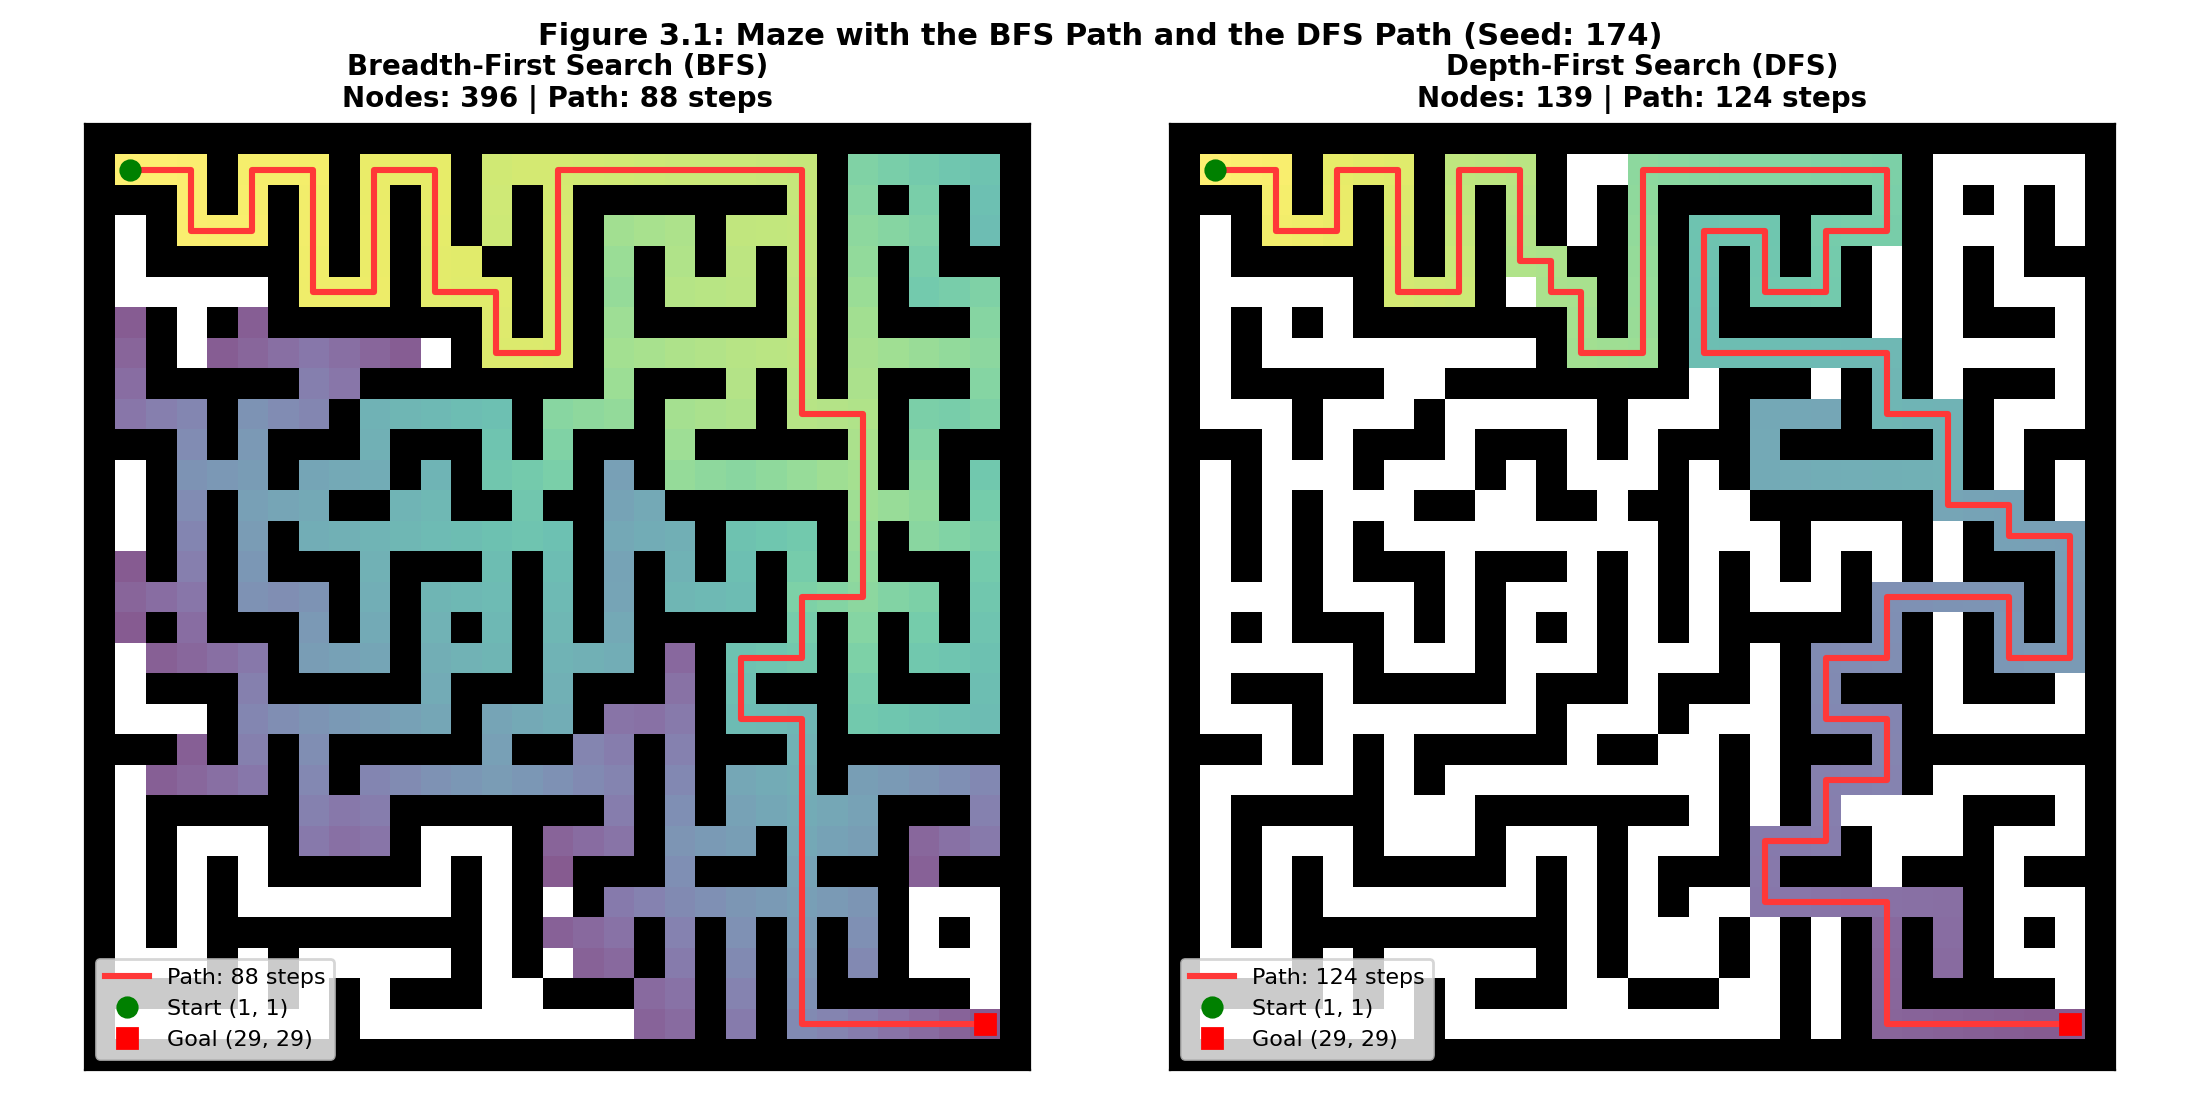

In [2]:
# Part 3: Figure 3.1 - Maze with BFS and DFS Paths
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), dpi=200)

for ax, res, title in zip(axes, [res_bfs, res_dfs], ['Breadth-First Search (BFS)', 'Depth-First Search (DFS)']):
    grid = np.full(maze.shape, np.nan)
    for (r, c), k in res['order'].items():
        grid[r, c] = k

    ax.imshow(maze, cmap='binary')
    im = ax.imshow(grid, cmap='viridis_r', alpha=0.65)
    
    path_r = [p[0] for p in res['path']]
    path_c = [p[1] for p in res['path']]
    ax.plot(path_c, path_r, color='#ff3838', lw=2.2, label=f"Path: {res['path_length']} steps")
    ax.plot(START[1], START[0], 'go', ms=7, label='Start (1, 1)')
    ax.plot(GOAL[1], GOAL[0], 'rs', ms=7, label=f'Goal ({GOAL[0]}, {GOAL[1]})')

    ax.set_title(f"{title}\nNodes: {res['nodes_expanded']} | Path: {res['path_length']} steps", fontsize=10, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(loc='lower left', fontsize=8)

plt.suptitle('Figure 3.1: Maze with the BFS Path and the DFS Path (Seed: 174)', fontsize=11, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig3_1_maze_paths.png"))
plt.close()

# -------------------------------------------------------------
# Part 4: Figure 3.2 - Frontier Size vs Expansion Step
# -------------------------------------------------------------
plt.figure(figsize=(8.5, 4.2), dpi=200)
plt.plot(res_bfs['frontier_history'], color='#1f77b4', lw=1.5, label=f"BFS (Max frontier = {res_bfs['max_frontier']})")
plt.plot(res_dfs['frontier_history'], color='#d62728', lw=1.2, label=f"DFS (Max frontier = {res_dfs['max_frontier']})")
plt.title('Figure 3.2: Frontier Size Against Expansion Step for BFS and DFS', fontsize=11, fontweight='bold')
plt.xlabel('Expansion Step', fontsize=10)
plt.ylabel('Frontier Queue / Stack Size', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig3_2_frontier_size.png"))
plt.close()

print("\nSaved fig3_1_maze_paths.png and fig3_2_frontier_size.png successfully.")
